# 2. Who the customers are, and what sells together

Two questions a shop owner would ask of this data.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shoplens.clean import load, clean

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
money = lambda v, _=None: f"£{v:,.0f}"

raw = load("data/online_retail.parquet")
sales, removed = clean(raw)
from shoplens.customers import summarize, group, by_group, repeat_buying, GROUPS
from shoplens.baskets import pairs
COLORS = dict(zip(GROUPS, [JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))

## Customer groups

Each customer is described by three things: days since their last order, how many orders they have placed, and how much they have spent. They are then sorted into six groups with plain names.

The first version of this project used a clustering method and got three unnamed segments. Named groups built from simple rules are easier to explain and to act on, and notebook 3 checks that they mean something.

In [2]:
customers = summarize(sales)
customers["group"] = group(customers)
table = by_group(customers)
table.style.format({"customers": "{:,.0f}", "spend": "£{:,.0f}", "typical_orders": "{:.0f}", "typical_days_since": "{:.0f}", "share_of_customers": "{:.0%}", "share_of_spend": "{:.0%}"})

,customers,spend,typical_orders,typical_days_since,share_of_customers,share_of_spend
group,,,,,,
Best customers,"1,115","£5,662,089",7,10,26%,68%
Regulars,825,"£1,148,602",3,37,19%,14%
New,234,"£80,716",1,18,5%,1%
Occasional,420,"£206,768",1,49,10%,2%
Going quiet,654,"£732,613",3,132,15%,9%
Lost,"1,076","£442,066",1,218,25%,5%


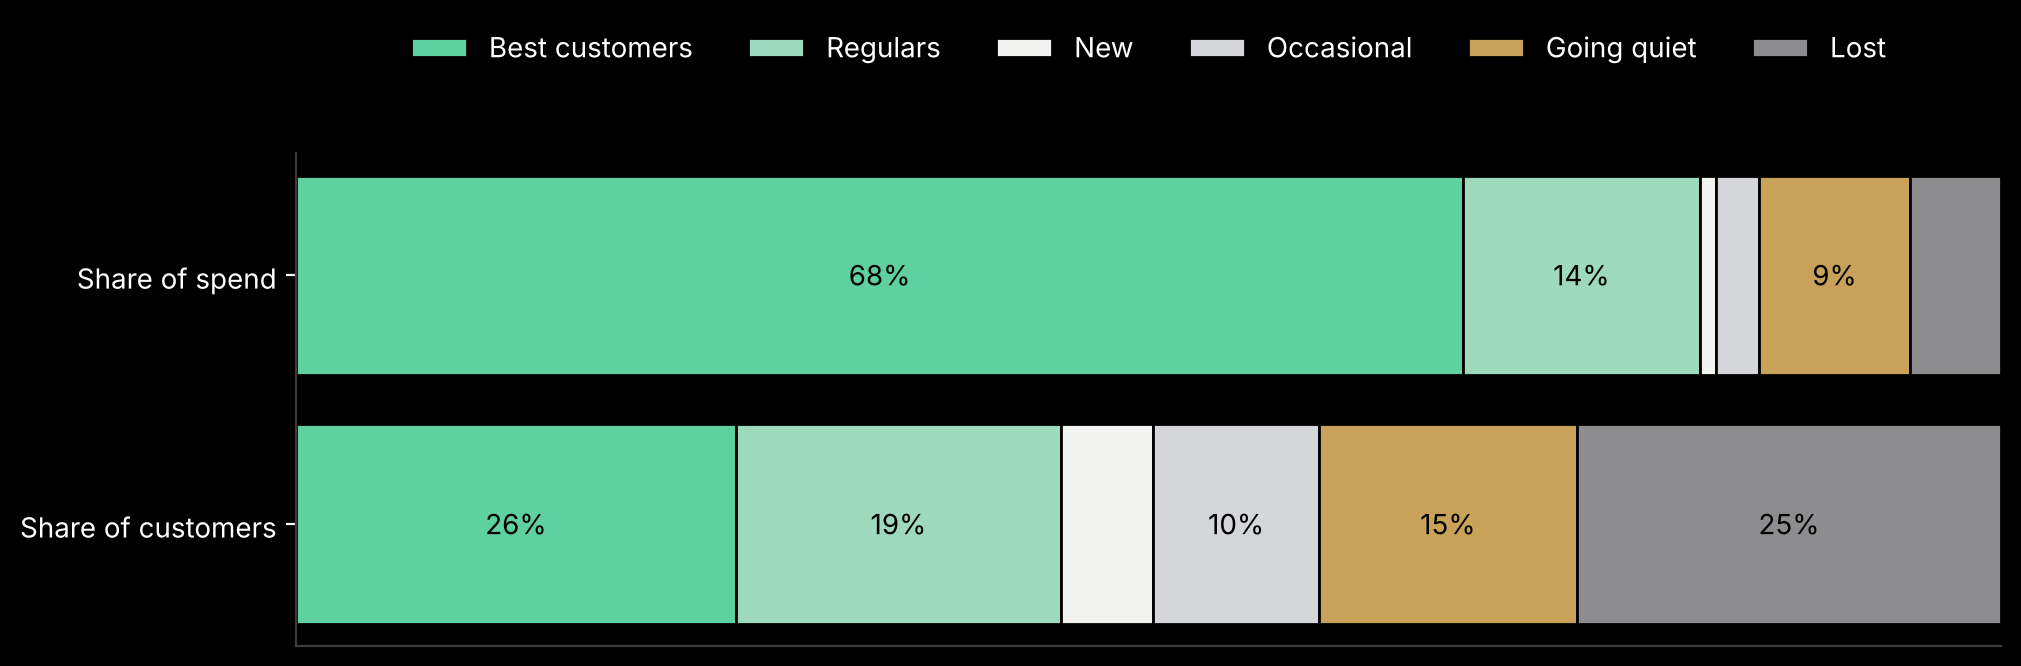

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for row, column in enumerate(["share_of_customers", "share_of_spend"]):
    left = 0
    for name in table.index:
        ax.barh(row, table.loc[name, column], left=left, color=COLORS[name], edgecolor="black", label=name if row == 0 else None)
        if table.loc[name, column] > 0.06:
            ax.text(left + table.loc[name, column] / 2, row, f"{table.loc[name, column]:.0%}", ha="center", va="center", color="black", fontsize=10)
        left += table.loc[name, column]
ax.set_yticks([0, 1], ["Share of customers", "Share of spend"]); ax.set_xlim(0, 1); ax.xaxis.set_visible(False); ax.grid(False)
ax.legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.3))
plt.show()

A quarter of the customers bring in more than two thirds of the money.

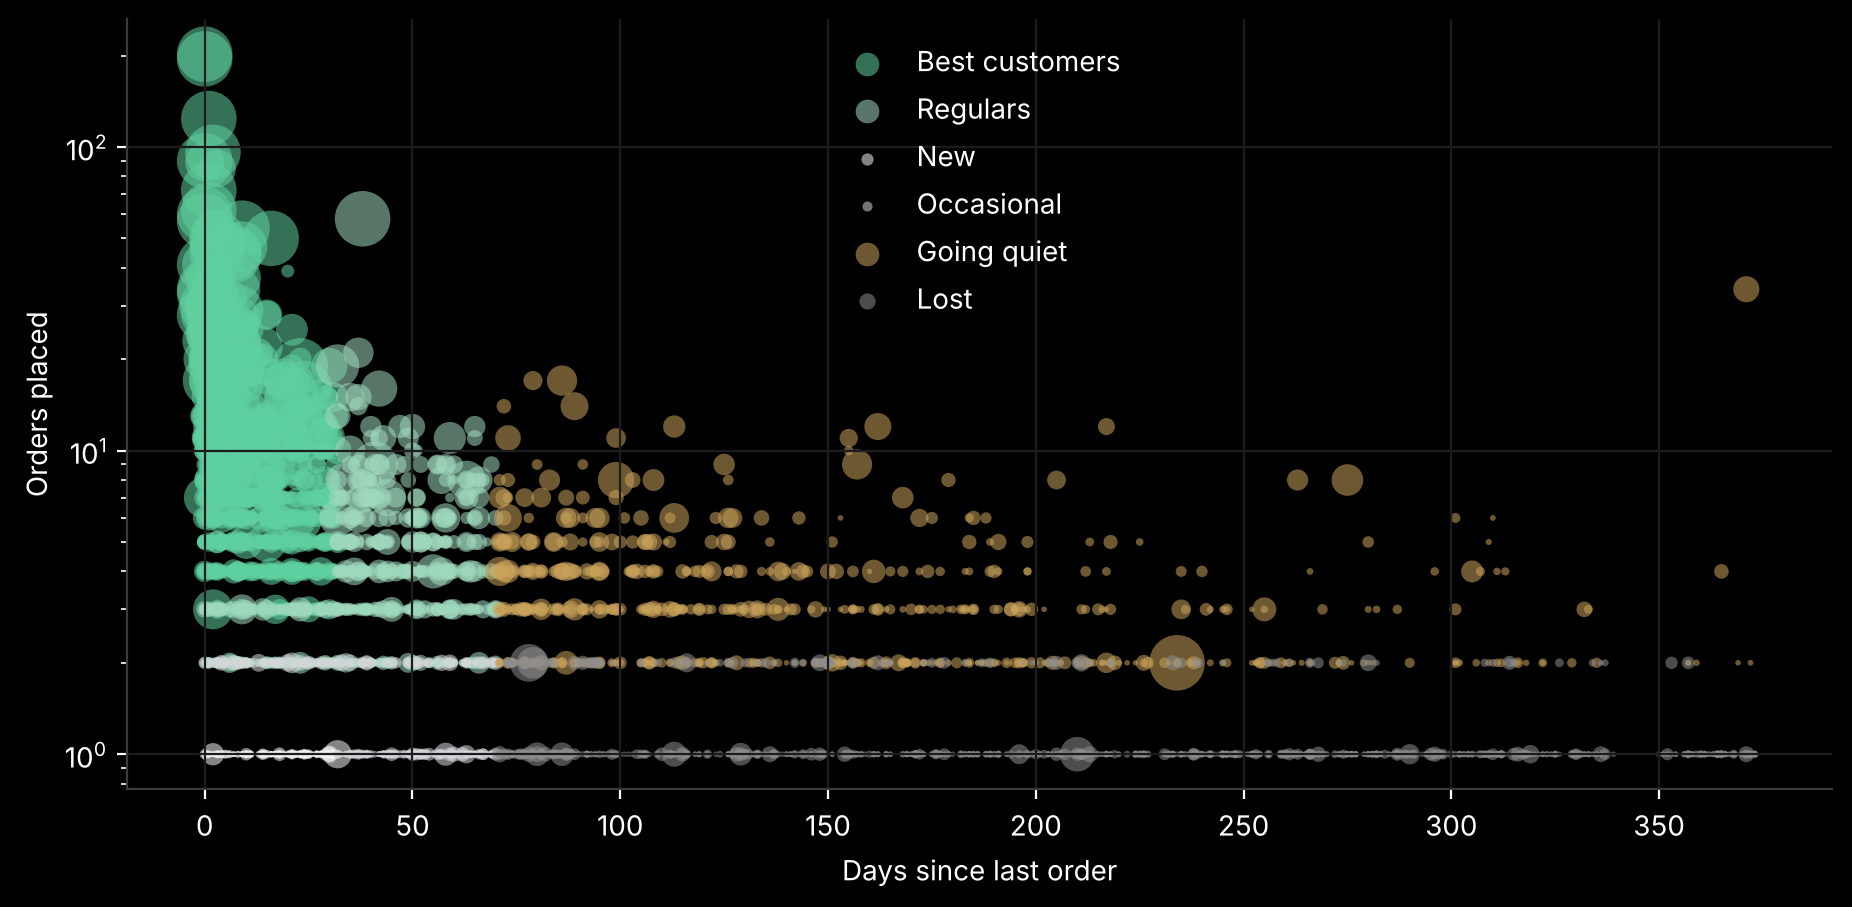

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in GROUPS:
    part = customers[customers.group == name]
    ax.scatter(part.days_since, part.orders, s=np.clip(part.spend / 60, 4, 400), color=COLORS[name], alpha=0.55, linewidths=0, label=name)
ax.set_yscale("log"); ax.set_xlabel("Days since last order"); ax.set_ylabel("Orders placed"); ax.legend(frameon=False, markerscale=0.6)
plt.show()

Each dot is a customer and its size is their spend. **Going quiet** is the group to watch: people who ordered several times and have not been back in months.

In [5]:
quiet = customers[customers.group == "Going quiet"].nlargest(10, "spend")[["orders", "spend", "days_since"]]
quiet.style.format({"spend": "£{:,.0f}", "orders": "{:.0f}", "days_since": "{:.0f}"})

,orders,spend,days_since
customer,,,
15749,2,"£24,851",234
16180,8,"£10,227",99
13093,8,"£7,798",275
16745,17,"£7,171",86
12980,9,"£7,092",157
13027,6,"£6,912",113
16182,4,"£6,618",71
15939,14,"£6,087",89
14101,6,"£5,977",73


## Do customers come back?

Each row is the set of customers who placed their first order in that month. Each column is a later month. The number is the share of them who ordered again.

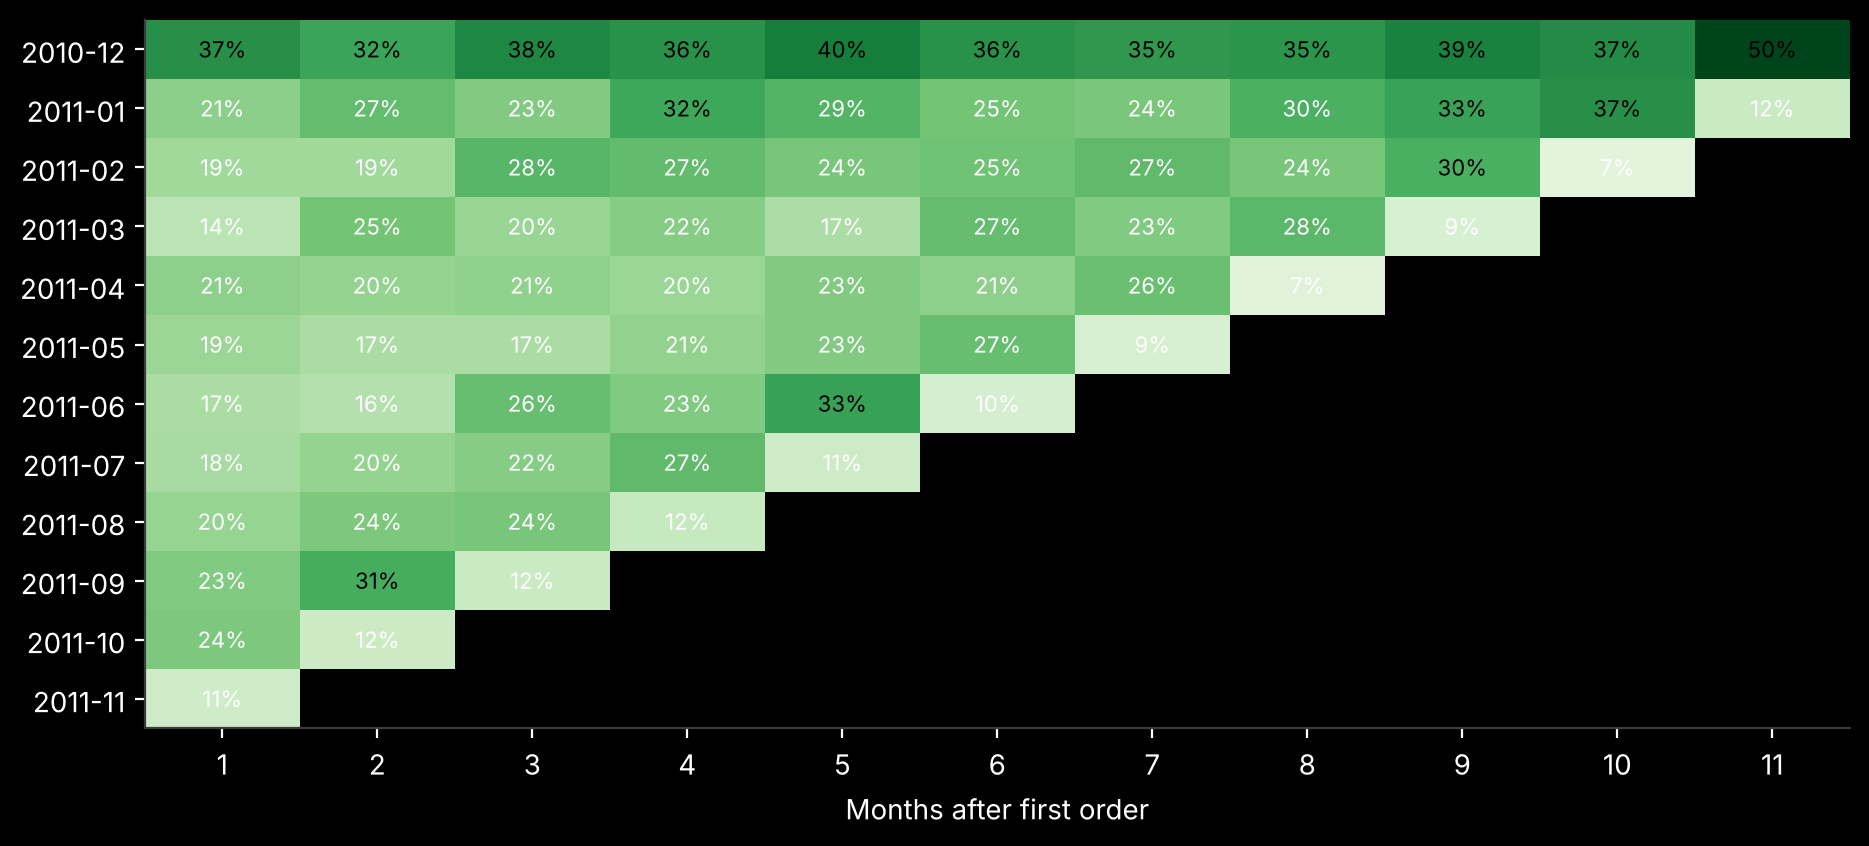

In [6]:
back = repeat_buying(sales).iloc[:-1, 1:12]
fig, ax = plt.subplots(figsize=(11, 4.6))
shown = ax.imshow(back.to_numpy(float), cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(back.shape[1]), back.columns); ax.set_yticks(range(len(back)), [str(m) for m in back.index]); ax.grid(False)
ax.set_xlabel("Months after first order")
for (i, j), v in np.ndenumerate(back.to_numpy(float)):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v < 0.3 else "black", fontsize=8)
plt.show()

Customers who first bought in December 2010 kept returning at 30 to 50 percent a month. Later groups return at about half that rate. The earliest group likely includes long standing customers whose history starts before the data does.

## What sells together

For every pair of products: how many orders hold both, and **lift**, which is how many times more often they appear together than they would by chance. A lift of 1 means no connection.

In [7]:
found = pairs(sales)
show = found.head(12).assign(pair=lambda t: t.name_a.str.title().str.strip() + "  +  " + t.name_b.str.title().str.strip())
show[["pair", "together", "chance_a_then_b", "lift"]].style.format({"together": "{:,.0f}", "chance_a_then_b": "{:.0%}", "lift": "{:.0f}x"}).hide(axis="index")

pair,together,chance_a_then_b,lift
Regency Tea Plate Green + Regency Tea Plate Pink,201,75%,58x
Regency Milk Jug Pink + Regency Sugar Bowl Green,205,76%,49x
Set Of 3 Wooden Stocking Decoration + Set Of 3 Wooden Tree Decorations,181,66%,47x
Regency Tea Plate Roses + Regency Tea Plate Pink,195,60%,47x
"Key Fob , Shed + Key Fob , Back Door",165,62%,46x
Set/10 Pink Polkadot Party Candles + Set/10 Blue Polkadot Party Candles,180,60%,46x
Set Of 3 Wooden Sleigh Decorations + Set Of 3 Wooden Tree Decorations,161,65%,46x
Regency Tea Plate Roses + Regency Tea Plate Green,227,70%,45x
Poppy'S Playhouse Bedroom + Poppy'S Playhouse Livingroom,203,65%,45x
Set/6 Red Spotty Paper Plates + Set/6 Red Spotty Paper Cups,236,73%,44x


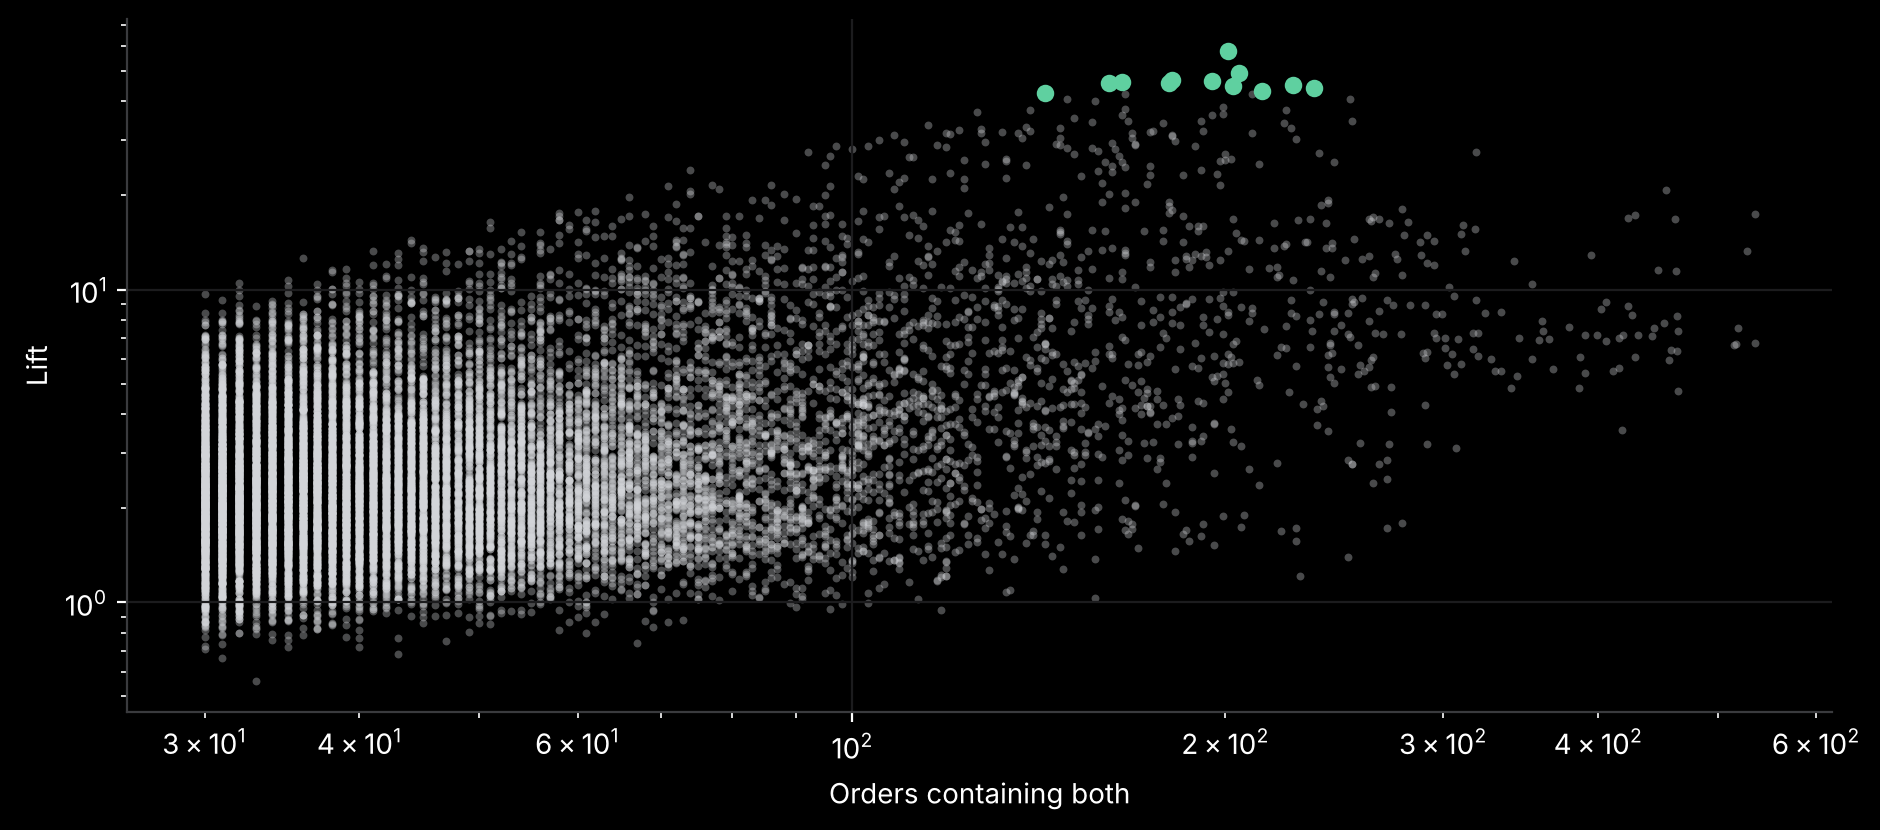

20,148 pairs share at least 30 orders


In [8]:
fig, ax = plt.subplots()
ax.scatter(found.together, found.lift, s=8, color=SILVER, alpha=0.35, linewidths=0)
ax.scatter(found.head(12).together, found.head(12).lift, s=28, color=JADE)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Orders containing both"); ax.set_ylabel("Lift")
plt.show()
print(f"{len(found):,} pairs share at least 30 orders")

## What this says

* **A quarter of customers are worth two thirds of the revenue.** Keeping them matters more than anything else here.
* **About 650 customers are going quiet.** They have ordered several times and spent real money. A list like the one above is where a shop would start.
* **The strongest pairs are sets sold as separate items**: tea plates in three colors, herb markers, matching decorations. Someone who buys one color is very likely to want the others, so these are natural bundles and natural suggestions at checkout.

All of this describes the past. Notebook 3 checks it against what happened next.